# Constructing fractional differences from binomial weights

A fractional difference combines the present level with a weighted history whose weights follow the binomial rule:

$$
(1-B)^d X_t=sum_{k=0}^{infty}omega_k X_{t-k},qquad
omega_0=1,qquad
omega_k=-\omega_{k-1}\frac{d-k+1}{k}.
$$

Here, $X_t$ is the value at time $t$; $B$ shifts a value back one time step, so $B^kX_t=X_{t-k}.$ $d\geq0$ is the difference order; $k$ is the lag; $\omega_k$ is the weight on the value $k$ steps back.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
from scipy.signal import fftconvolve
from statsmodels.tsa.stattools import adfuller

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.data.differentiation import adaptive_fractional_difference, calculate_weights_ffd, calculate_weights_std, fractional_difference_fixed, fractional_difference_fixed_single, fractional_difference_std

FIGURES = ROOT / "outputs" / "figures" / "08_fractional_differentiation"
TABLES = ROOT / "outputs" / "tables" / "08_fractional_differentiation"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def natural_weights(degree, size):
    values = [1.0]
    for k in range(1, size):
        values.append(-values[-1] * (degree - k + 1) / k)
    return np.asarray(values, dtype=float)

def adf_record(values):
    result = adfuller(np.asarray(values, dtype=float), maxlag=1, regression="c", autolag=None)
    return {"ADF statistic": float(result[0]), "p-value": float(result[1]), "Used lag": int(result[2]), "Observations in test": int(result[3]), "Five percent critical value": float(result[4]["5%"]) }

raw = raw.sort_values("time").dropna(subset=["time", "close"]).drop_duplicates("time").reset_index(drop=True)
minute_close = pd.Series(raw["close"].to_numpy(dtype=float), index=pd.DatetimeIndex(raw["time"]), name="One-minute close")
close = minute_close.resample("15min").last().dropna().rename("Fifteen-minute close")
log_price = np.log(close).rename("Log price")
log_frame = log_price.rename("close").to_frame()
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## From Integer Steps to Fractional Steps

In [2]:
data_provenance = pd.DataFrame({
    "Field": ["Archive", "Provider", "Public access", "Market", "Minute records", "Analysis interval", "Analysis records", "First analysis time", "Last analysis time", "Archive SHA256"],
    "Value": ["BTCUSDT-1m-2021-01.zip", "Binance Data Vision", "Direct public download", "Bitcoin quoted in USDT", f"{len(minute_close):,}", "Fifteen minutes", f"{len(close):,}", str(close.index.min()), str(close.index.max()), data_hash],
})
degrees = [0.0, 0.1, 0.2, 0.5, 0.8, 1.0]
boundary_rows = []
for degree in [0.0, 0.5, 1.0]:
    weights = natural_weights(degree, 6)
    for lag, value in enumerate(weights):
        boundary_rows.append({"Order": degree, "Lag": lag, "Weight": value})
boundary_weights = pd.DataFrame(boundary_rows)
recurrence_rows = []
for degree in degrees:
    direct = natural_weights(degree, 80)
    released = calculate_weights_std(degree, 80).flatten()[::-1]
    recurrence_rows.append({"Order": degree, "Largest absolute difference": np.max(np.abs(direct - released)), "First weight": direct[0], "Second weight": direct[1], "Partial sum through lag 79": direct.sum()})
recurrence_check = pd.DataFrame(recurrence_rows)
decay_rows = []
for degree in [0.1, 0.2, 0.5, 0.8]:
    weights = natural_weights(degree, 2000)
    decay_rows.append({"Order": degree, "Weight at lag 1": weights[1], "Weight at lag 10": weights[10], "Weight at lag 100": weights[100], "Partial sum through lag 1999": weights.sum(), "Absolute weight mass": np.abs(weights).sum()})
weight_decay_summary = pd.DataFrame(decay_rows)
save_table(data_provenance, "data_provenance", "Public data used in Chapter 7.", "tab:chapter7-data-provenance", fit=True)
save_table(boundary_weights, "boundary_weights", "First six weights for the two endpoint orders and one fractional order.", "tab:chapter7-boundary-weights", fit=False)
save_table(recurrence_check, "recurrence_check", "Independent and released binomial-weight calculations.", "tab:chapter7-recurrence-check", fit=True)
save_table(weight_decay_summary, "weight_decay_summary", "Decay of fractional weights over long lags.", "tab:chapter7-weight-decay", fit=True)
display(data_provenance)
display(boundary_weights.round(8))
display(recurrence_check.round(12))
display(weight_decay_summary.round(8))

,Field,Value
0,Archive,BTCUSDT-1m-2021-1zip
1,Provider,Binance Data Vision
2,Public access,Direct public download
3,Market,Bitcoin quoted in USDT
4,Minute records,"44,640"
5,Analysis interval,Fifteen minutes
6,Analysis records,"2,976"
7,First analysis time,2021-01-01 00:00:00
8,Last analysis time,2021-01-31 23:45:00
9,Archive SHA256,9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A2...


,Order,Lag,Weight
0,0,0,1
1,0,1,0
2,0,2,0
3,0,3,0
4,0,4,0
5,0,5,0
6,0.5,0,1
7,0.5,1,-0.500000
8,0.5,2,-0.125000
9,0.5,3,-0.062500


,Order,Largest absolute difference,First weight,Second weight,Partial sum through lag 79
0,0,0,1,0,1
1,0.1,0,1,-0.1,0.604176
2,0.2,0,1,-0.2,0.358094
3,0.5,0,1,-0.5,0.063376
4,0.8,0,1,-0.8,0.006600
5,1,0,1,-1,0


,Order,Weight at lag 1,Weight at lag 10,Weight at lag 100,Partial sum through lag 1999,Absolute weight mass
0,0.1,-0.1,-0.007475,-0.000591,0.437605,1.562395
1,0.2,-0.2,-0.010973,-0.000685,0.187837,1.812163
2,0.5,-0.5,-0.009274,-0.000283,0.012618,1.987382
3,0.8,-0.8,-0.002978,-0.000044,0.000498,1.999502


## Boundary Cases

Order zero leaves the series unchanged, while order one gives the ordinary first difference:

$$
(1-B)^0X_t=X_t,qquad
(1-B)^1X_t=X_t-X_{t-1}.
$$

Here, $X_t$ is the current level; $X_{t-1}$ is the preceding level; $B$ is the one-step backshift. $d=0$ is the unchanged endpoint and $d=1$ is the first-difference endpoint.

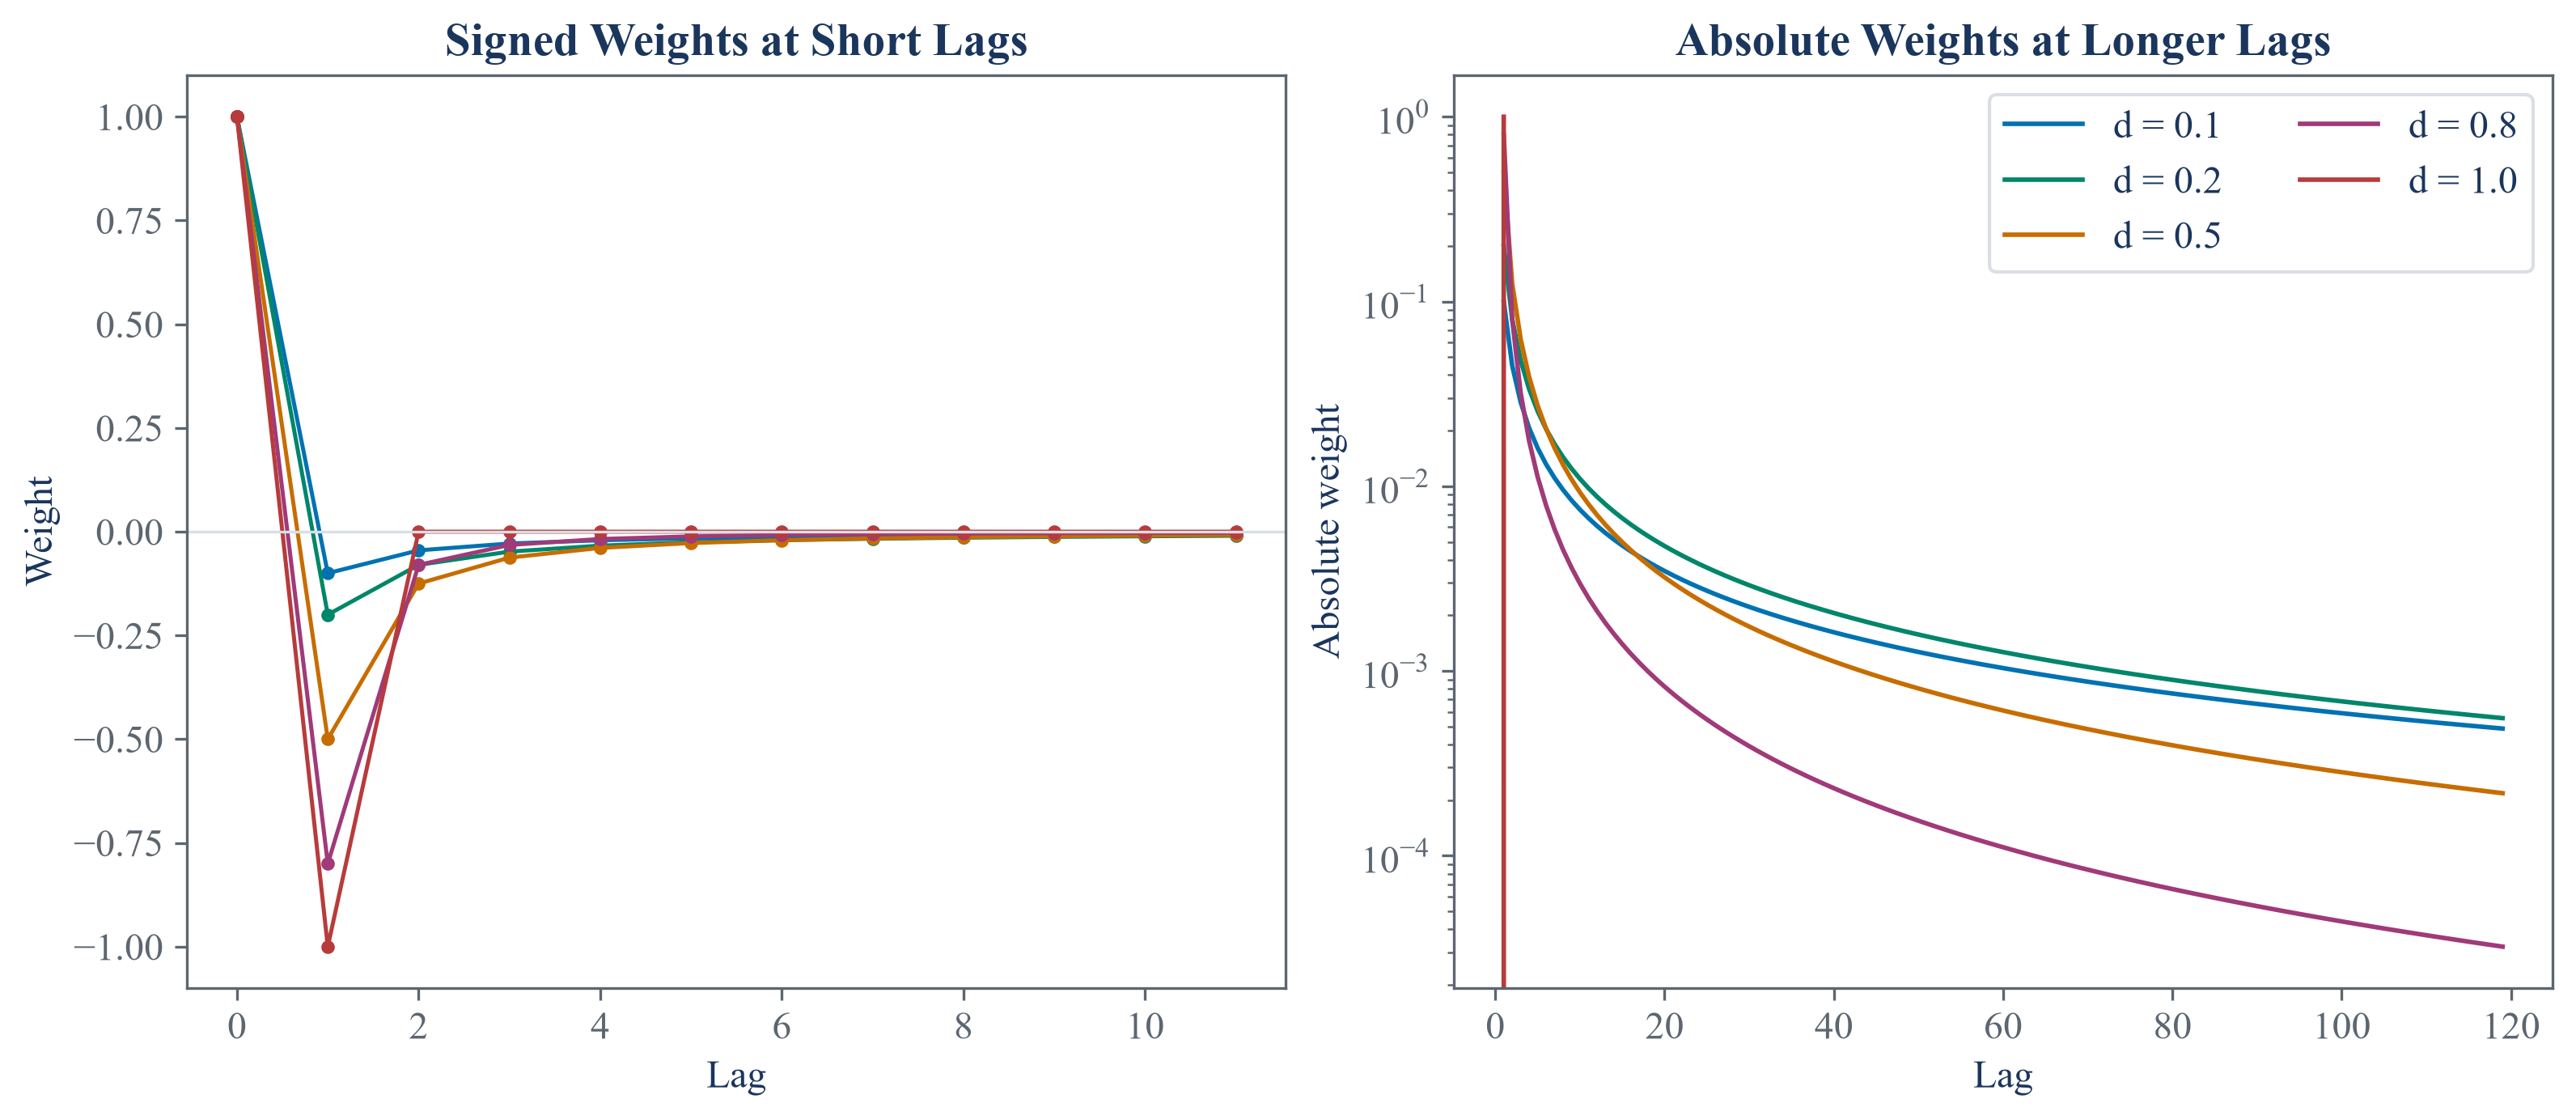

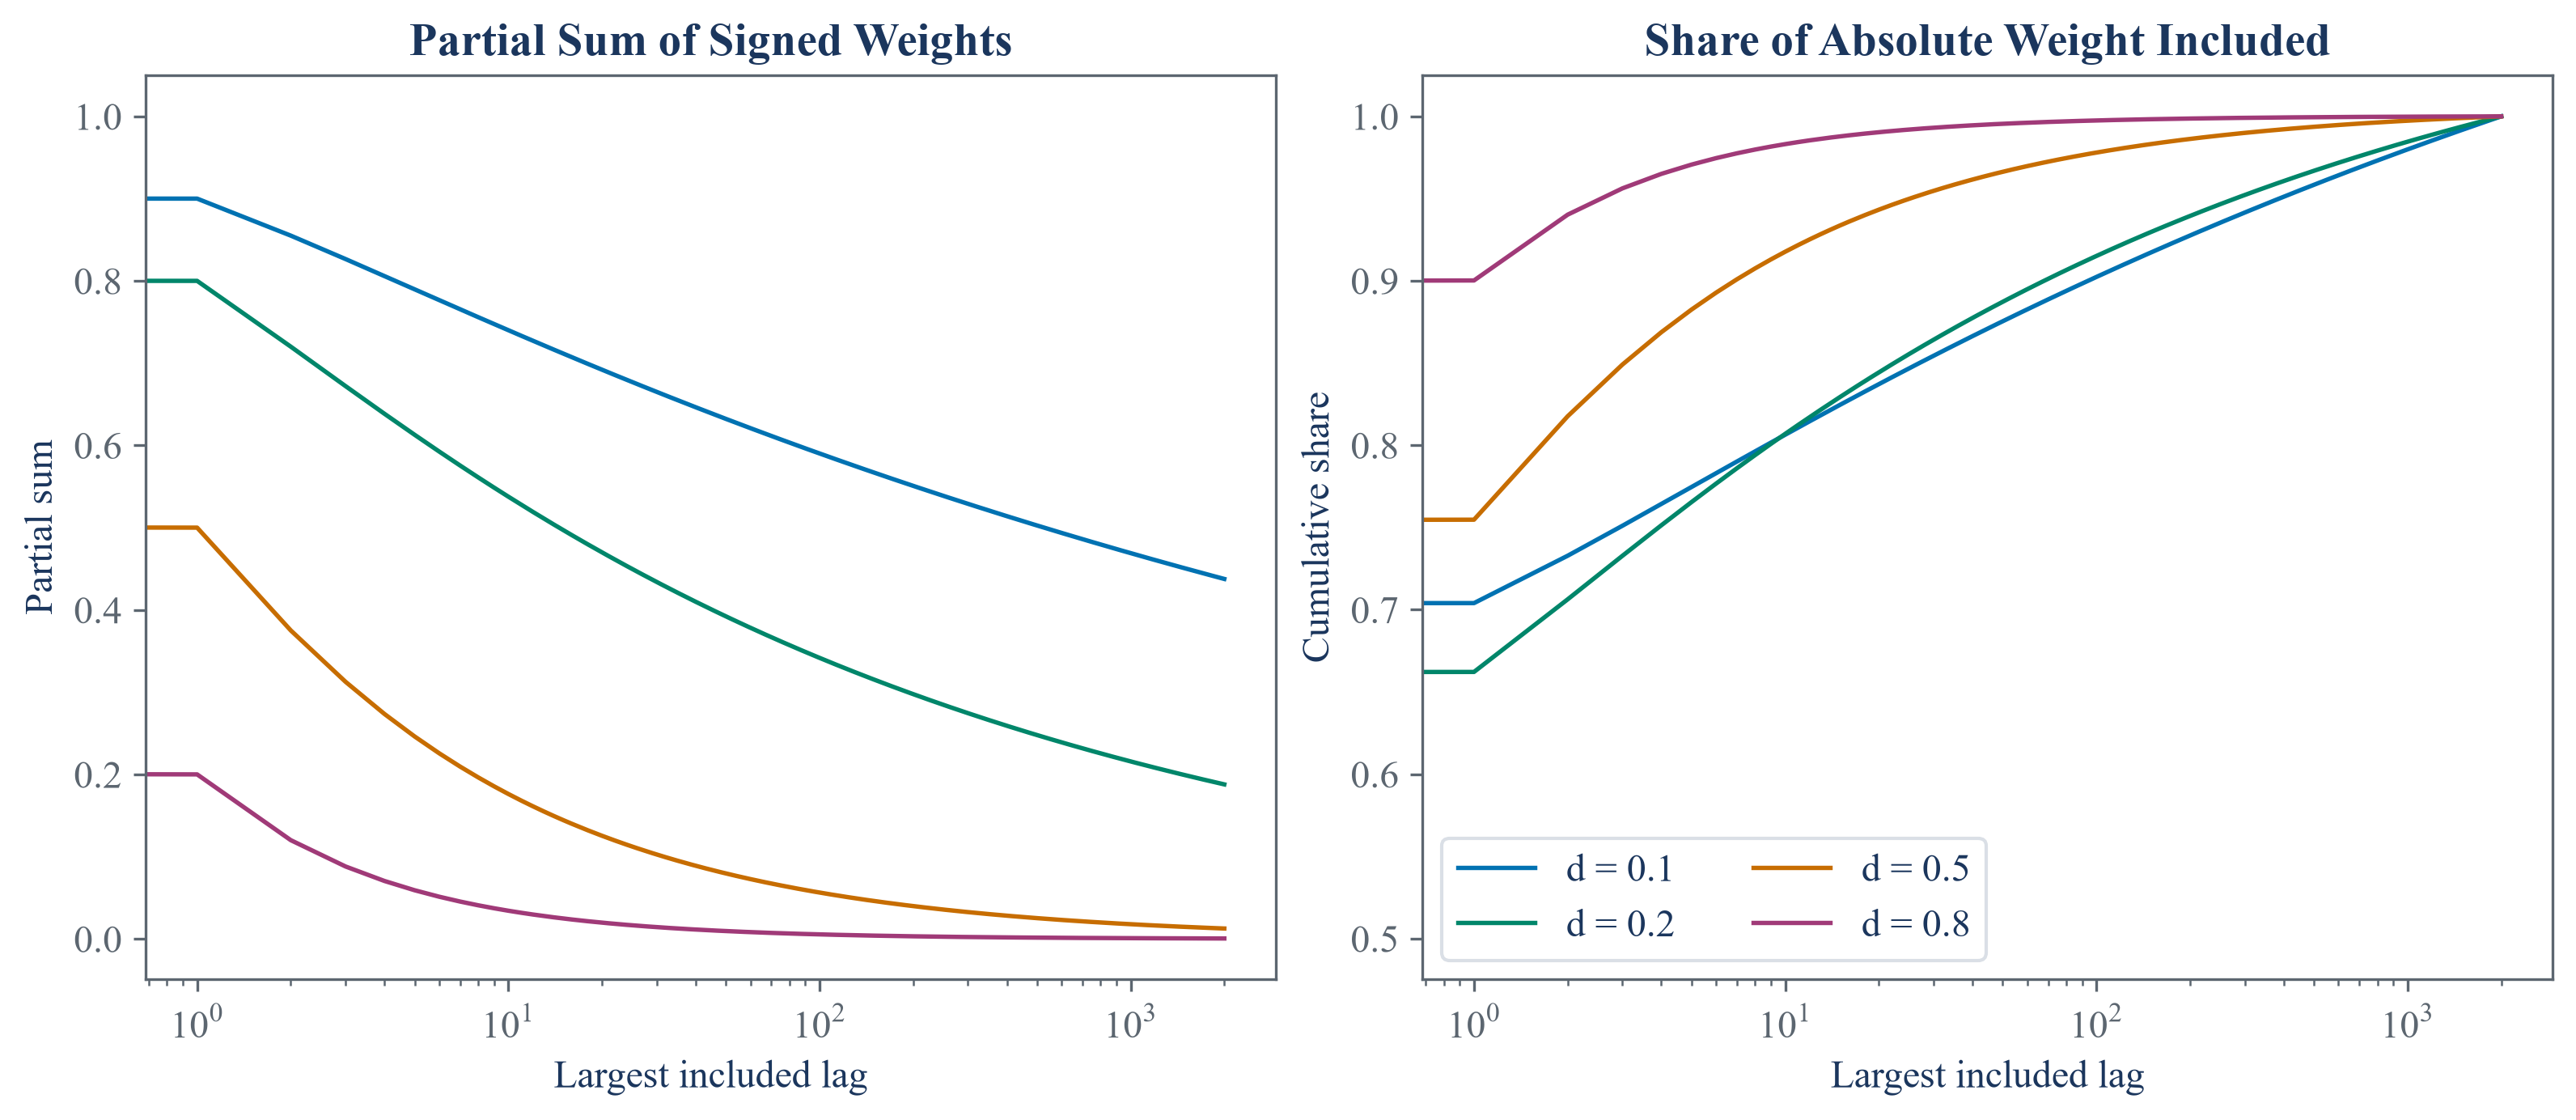

In [3]:
plot_degrees = [0.1, 0.2, 0.5, 0.8, 1.0]
colors = [palette["cyan"], palette["green"], palette["amber"], palette["violet"], palette["rose"]]
figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
for degree, color in zip(plot_degrees, colors):
    weights = natural_weights(degree, 120)
    axes[0].plot(np.arange(12), weights[:12], marker="o", markersize=3, linewidth=1.2, color=color, label=f"d = {degree:.1f}")
    axes[1].plot(np.arange(1, 120), np.abs(weights[1:]), linewidth=1.35, color=color, label=f"d = {degree:.1f}")
axes[0].axhline(0, color=palette["grid"], linewidth=0.8)
axes[0].set_title("Signed Weights at Short Lags")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Weight")
axes[1].set_yscale("log")
axes[1].set_title("Absolute Weights at Longer Lags")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Absolute weight")
axes[1].legend(ncol=2)
figure.savefig(FIGURES / "binomial_weights.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "binomial_weights.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "binomial_weights.png")))
plt.close(figure)

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
for degree, color in zip(plot_degrees[:-1], colors[:-1]):
    weights = natural_weights(degree, 2000)
    axes[0].plot(np.arange(2000), np.cumsum(weights), linewidth=1.3, color=color, label=f"d = {degree:.1f}")
    axes[1].plot(np.arange(2000), np.cumsum(np.abs(weights)) / np.abs(weights).sum(), linewidth=1.3, color=color, label=f"d = {degree:.1f}")
axes[0].set_xscale("log")
axes[0].set_title("Partial Sum of Signed Weights")
axes[0].set_xlabel("Largest included lag")
axes[0].set_ylabel("Partial sum")
axes[1].set_xscale("log")
axes[1].set_title("Share of Absolute Weight Included")
axes[1].set_xlabel("Largest included lag")
axes[1].set_ylabel("Cumulative share")
axes[1].legend(ncol=2)
figure.savefig(FIGURES / "partial_weight_sums.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "partial_weight_sums.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "partial_weight_sums.png")))
plt.close(figure)

## Tracing fractional weights across long lags

For an order strictly between zero and one, every lagged weight is negative and its magnitude eventually declines toward zero:

$$
0<d<1\Longrightarrow -1<\omega_k<0\ (k\geq1),qquad
\left|\frac{\omega_k}{\omega_{k-1}}\right|=\frac{k-1-d}{k}<1\ (k\geq2),qquad
\lim_{k\to\infty}\omega_k=0.
$$

Here, $d\in(0,1)$ is the fractional order; $k\geq1$ is the lag; $\omega_k$ is the lag-$k$ weight. $|\cdot|$ is absolute value; the displayed ratio compares two consecutive weight magnitudes.

## Tests

In [4]:
w_zero = calculate_weights_std(0.0, 8).flatten()[::-1]
w_one = calculate_weights_std(1.0, 8).flatten()[::-1]
w_half = calculate_weights_std(0.5, 2000).flatten()[::-1]
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert len(minute_close) == 44640
assert len(close) == 2976
assert close.index.is_monotonic_increasing
assert not close.isna().any()
assert np.array_equal(w_zero, np.array([1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]))
assert np.array_equal(w_one, np.array([1.0, -1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]))
assert np.array_equal(calculate_weights_ffd(0.0, 1e-5).flatten(), np.array([1.0]))
assert np.array_equal(calculate_weights_ffd(1.0, 1e-5).flatten(), np.array([-1.0, 1.0]))
assert np.max(recurrence_check["Largest absolute difference"]) < 1e-15
assert np.all(w_half[1:] < 0.0)
assert np.all(np.diff(np.abs(w_half[1:])) < 0.0)
assert np.all(np.cumsum(w_half) > 0.0)
assert np.cumsum(w_half)[-1] < 0.02
assert np.isclose(boundary_weights.query("Order == 0.5 and Lag == 2")["Weight"].iloc[0], -0.125)
assert len(weight_decay_summary) == 4
assert (FIGURES / "binomial_weights.pdf").is_file()
assert (FIGURES / "partial_weight_sums.pdf").is_file()